# Figure 4: the 8 May 2023 overpass (Cal/Val pass 26)

(a) The observed section along the mooring line from the 11 moorings; (b) the network applied to every 2 km pixel
of the swath with SWOT as input: the SSHA it was given on top of the block, the density anomaly on its faces, and the
section along the mooring line (red dashed); (c) the network trained and run with the DUACS SSHA interpolated to the
swath pixels; (d) GLORYS12 interpolated to the swath pixels. Black contours are the density anomaly every
0.1 kg/m3; the RMSE of each section at the moorings is printed on the panel.

This notebook runs the trained network on the overpass (a few seconds on a CPU).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
from swot2argo import data, models, evaluate, gradients, plots
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
T = data.tests()

In [2]:
G = data.swath("swath_20230508_13.npz")
S = data.swath_pixels(G)
m_swot = models.load("../results/models/headline_swot.pt")
m_duacs = models.load("../results/models/headline_duacs.pt")
print(m_swot); print(m_duacs); print(f"{S.n} valid pixels on the overpass of {G['time']}, pass {G['pass_num']}")

<Network SSH + SST + MDT -> 4 modes, 15 members, pretrained on DUACS, fine-tuned on SWOT>
<Network SSH + SST + MDT -> 4 modes, 15 members, pretrained on DUACS, fine-tuned on DUACS>
3779 valid pixels on the overpass of 2023-05-08T13:18:36, pass 26


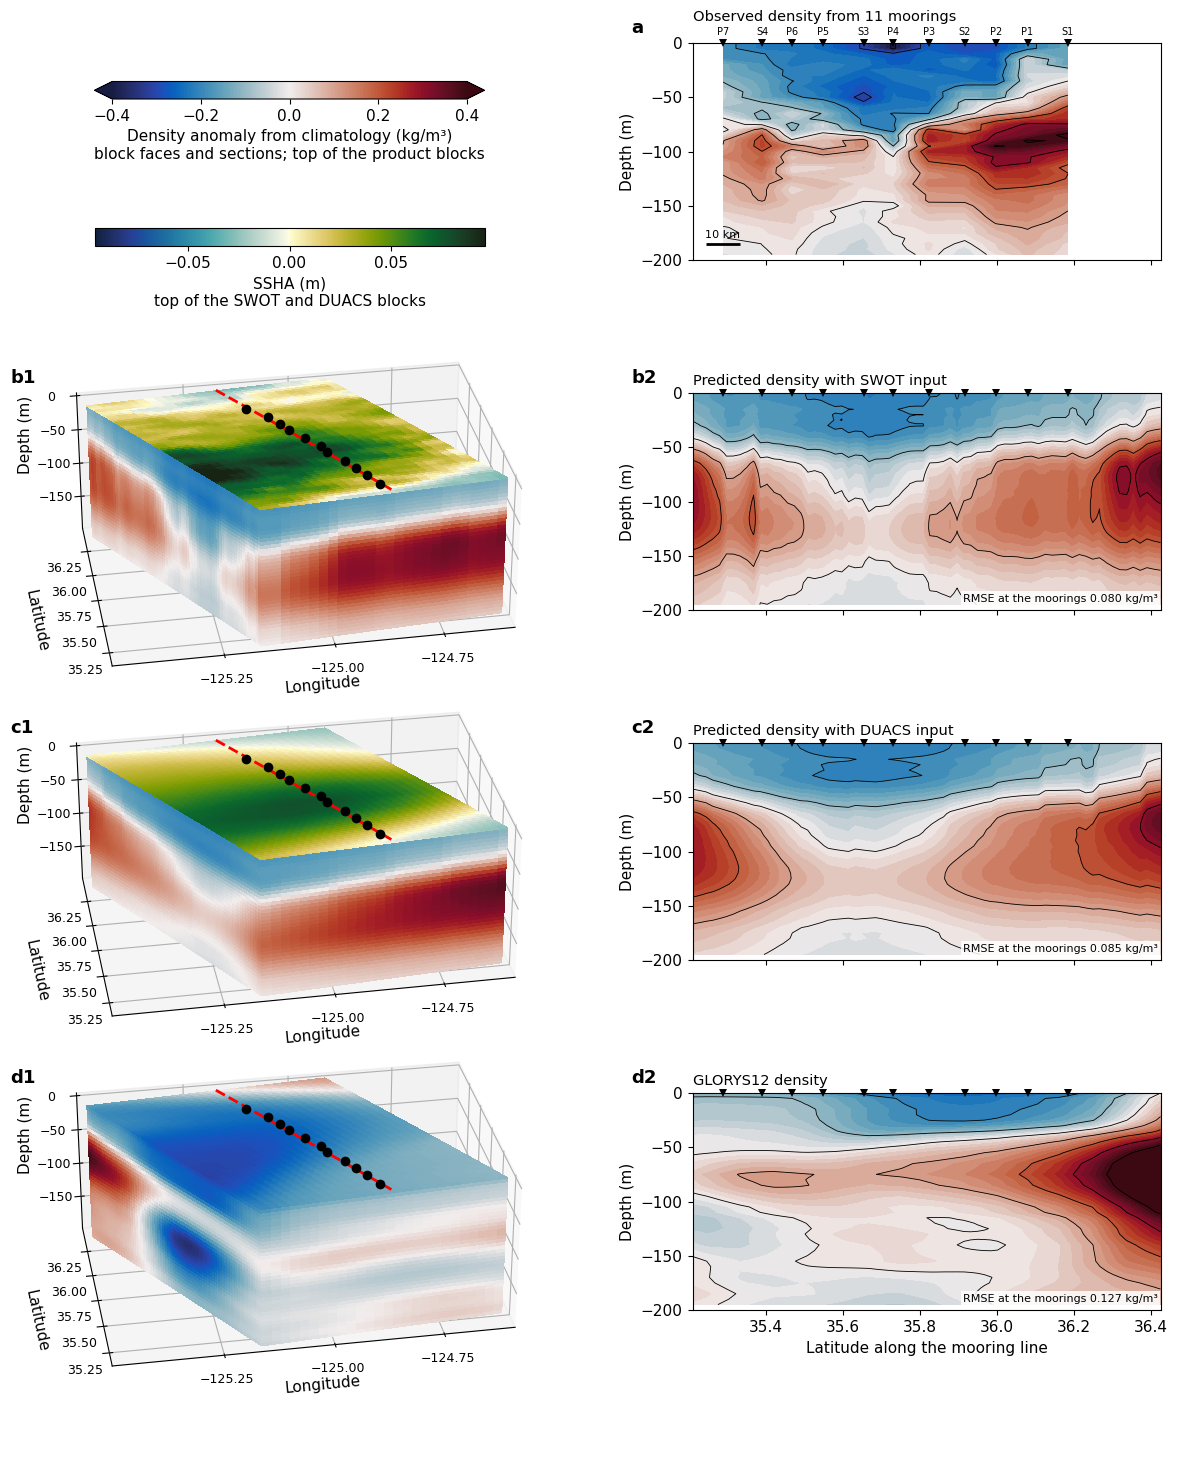

Predicted density with SWOT input: RMSE along the mooring line 0.080 kg/m3
Predicted density with DUACS input: RMSE along the mooring line 0.085 kg/m3
GLORYS12 density: RMSE along the mooring line 0.127 kg/m3


In [3]:
sources = plots.swath_sources(S, G, m_swot, m_duacs)
fig, rmses = plots.swath_compare(S, G, sources, T); plt.show()
for k, v in rmses.items(): print(f"{k}: RMSE along the mooring line {v:.3f} kg/m3")